<b><h1 style="text-align: center;">PENERAPAN KOMBINASI METODE RESNET DAN BI-GRU UNTUK KLASIFIKASI GENRE MUSIK BERBASIS FUSI CITRA SCALOGRAM-SPECTROGRAM</h1></b>

---

<h5 style="text-align: right;">By Angela Adytha Putri</h5>

### Pipeline data

| Skrip | Tahap |
|---|---|
| `1_generate_waveforms.py` | Visualisasi waveform per genre |
| `2_normalize_audio.py` | Normalisasi amplitudo audio |
| `3_generate_spectrogram_scalogram.py` | Spectrogram (STFT) dan scalogram (CWT, wavelet Morlet) grayscale |
| `4_crop_image_segments.py` | Potong tiap gambar 2240×224 menjadi 10 segmen 224×224 |
| `5_colorize_rgb_channels.py` | Scalogram → kanal merah, spectrogram → kanal hijau |
| `6_fusion_*.py` | Fusi kedua kanal (addition, average, division, max, min, multiplication, subtraction, weighted average) menjadi satu kanal |
| `7_merge_fusion_rgb.py` | Gabung jadi gambar RGB: R = scalogram, G = spectrogram, B = hasil fusi |
| `8_split_train_val_test.py` | Split per genre: 70% train, 20% validation, 10% test |

# **Section 0. Setup**

## **0.1 Import Library & Setup Device**

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import os
import time

from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Dataset, ConcatDataset
from torchvision import transforms, models, datasets
from torchinfo import summary
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## **0.2 Load Datasets**

Data berasal dari **7 sumber**, semuanya memakai fusi *weighted* dengan α = 0.5.

| Subset | Jumlah gambar |
|---|---|
| Train | 7.286 (6.986 split utama + 6 × 50) |
| Validation | 2.596 (1.996 split utama + 6 × 100) |
| Test | 3.098 (998 split utama + 6 × 350) |

Kelas (10): `blues`, `classical`, `country`, `disco`, `hiphop`, `jazz`, `metal`, `pop`, `reggae`, `rock`.

In [ ]:
# =========================
# PATH DATASET
# =========================

train_dirs = [
    "split/weighted/0.5/sekunder/train",
    "split/weighted/0.5/primer/0:30-1:00/train",
    "split/weighted/0.5/primer/1:00-1:30/train",
    "split/weighted/0.5/primer/1:30-2:00/train",
    "split/weighted/0.5/primer/2:00-2:30/train",
    "split/weighted/0.5/primer/2:30-3:00/train",
    "split/weighted/0.5/primer/reff/train"
]

val_dirs = [
    "split/weighted/0.5/sekunder/validation",
    "split/weighted/0.5/primer/0:30-1:00/validation",
    "split/weighted/0.5/primer/1:00-1:30/validation",
    "split/weighted/0.5/primer/1:30-2:00/validation",
    "split/weighted/0.5/primer/2:00-2:30/validation",
    "split/weighted/0.5/primer/2:30-3:00/validation",
    "split/weighted/0.5/primer/reff/validation"
]

test_dirs = [
    "split/weighted/0.5/sekunder/test",
    "split/weighted/0.5/primer/0:30-1:00/test",
    "split/weighted/0.5/primer/1:00-1:30/test",
    "split/weighted/0.5/primer/1:30-2:00/test",
    "split/weighted/0.5/primer/2:00-2:30/test",
    "split/weighted/0.5/primer/2:30-3:00/test",
    "split/weighted/0.5/primer/reff/test"
]

# =========================
# PARAMETER
# =========================
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_WORKERS = 2

# =========================
# TRANSFORM
# =========================

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9, 1.0)),
    transforms.ColorJitter(contrast=0.1),
    transforms.ToTensor()
])

test_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
])

# =========================
# LOAD TRAIN DATASET
# =========================
train_datasets = []
total_train = 0

for idx, tdir in enumerate(train_dirs):
    dset = datasets.ImageFolder(root=tdir, transform=train_transforms)
    train_datasets.append(dset)
    print(f"✅ Train dataset {idx+1}")
    print(f"   Jumlah data: {len(dset)}")
    total_train += len(dset)

train_dataset = ConcatDataset(train_datasets)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"📊 TOTAL DATA TRAIN: {total_train}")
print("")

# =========================
# LOAD VALIDATION DATASET
# =========================
val_datasets = []
total_val = 0

for idx, vdir in enumerate(val_dirs):
    dset = datasets.ImageFolder(root=vdir, transform=test_transforms)
    val_datasets.append(dset)
    print(f"✅ Validation dataset {idx+1}")
    print(f"   Jumlah data: {len(dset)}")
    total_val += len(dset)

val_dataset = ConcatDataset(val_datasets)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"📊 TOTAL DATA VALIDATION: {total_val}")
print("")

# =========================
# LOAD TEST DATASET
# =========================

test_datasets = []
test_loaders  = []
total_test = 0

for idx, tdir in enumerate(test_dirs):
    dset = datasets.ImageFolder(root=tdir, transform=test_transforms)
    loader = DataLoader(
        dset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    test_datasets.append(dset)
    test_loaders.append(loader)

    print(f"✅ Test dataset {idx+1} loaded")
    print(f"   Jumlah data: {len(dset)}")
    total_test += len(dset)

print(f"📊 TOTAL DATA TEST: {total_test}")

# =========================
# DAFTAR KELAS
# =========================

class_names = train_datasets[0].classes
print("\n🎯 Daftar kelas:", class_names)
print("🎯 Jumlah kelas:", len(class_names))

✅ Train dataset 1
   Jumlah data: 6986
✅ Train dataset 2
   Jumlah data: 50
✅ Train dataset 3
   Jumlah data: 50
✅ Train dataset 4
   Jumlah data: 50
✅ Train dataset 5
   Jumlah data: 50
✅ Train dataset 6
   Jumlah data: 50
✅ Train dataset 7
   Jumlah data: 50
📊 TOTAL DATA TRAIN: 7286

✅ Validation dataset 1
   Jumlah data: 1996
✅ Validation dataset 2
   Jumlah data: 100
✅ Validation dataset 3
   Jumlah data: 100
✅ Validation dataset 4
   Jumlah data: 100
✅ Validation dataset 5
   Jumlah data: 100
✅ Validation dataset 6
   Jumlah data: 100
✅ Validation dataset 7
   Jumlah data: 100
📊 TOTAL DATA VALIDATION: 2596

✅ Test dataset 1 loaded
   Jumlah data: 998
✅ Test dataset 2 loaded
   Jumlah data: 350
✅ Test dataset 3 loaded
   Jumlah data: 350
✅ Test dataset 4 loaded
   Jumlah data: 350
✅ Test dataset 5 loaded
   Jumlah data: 350
✅ Test dataset 6 loaded
   Jumlah data: 350
✅ Test dataset 7 loaded
   Jumlah data: 350
📊 TOTAL DATA TEST: 3098

🎯 Daftar kelas: ['blues', 'classical', 'country

# **Section 1. ResNet & Bi-GRU Architecture**

Model hibrida CNN + RNN:

1. **Backbone**: ResNet18 pretrained ImageNet, tanpa `avgpool` dan `fc`. Input 224×224 menghasilkan feature map 512×7×7.
2. **Pooling + BatchNorm + Dropout (0.1)** sebanyak tiga tahap berurutan. `AdaptiveMaxPool2d` mengecilkan feature map ke 4×4, sehingga dua tahap berikutnya tidak mengubah ukuran.
3. **Sequence**: feature map 512×4×4 di-reshape menjadi 16 langkah dengan 512 fitur.
4. **BiGRU**: 2 layer, hidden size 256, bidirectional. Hanya output langkah terakhir yang dipakai.
5. **Klasifier**: ReLU lalu `Linear(512 → 10)`.

Optimizer Adam (lr = 1e-4, weight decay = 1e-4) dan loss `CrossEntropyLoss`. Sel di bawah membuat model lalu menampilkan struktur dan ringkasan parameternya.

In [3]:
class ResGru(nn.Module):
    def __init__(self, num_classes=10, hidden_size=256, num_layers=2, bidirectional=True):
        super(ResGru, self).__init__()

        # --- 1. Backbone ResNet18 pretrained ---
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.feature_extractor = nn.Sequential(*list(resnet.children())[:-2])

        # --- 2. Pooling + BN + Dropout ---
        self.pool1 = nn.AdaptiveMaxPool2d((4, 4))
        self.bn1   = nn.BatchNorm2d(512)
        self.drop1 = nn.Dropout(0.1)

        self.pool2 = nn.AdaptiveMaxPool2d((4, 4))
        self.bn2   = nn.BatchNorm2d(512)
        self.drop2 = nn.Dropout(0.1)

        self.pool3 = nn.AdaptiveMaxPool2d((4, 4))
        self.bn3   = nn.BatchNorm2d(512)
        self.drop3 = nn.Dropout(0.1)

        # --- 3. BiGRU ---
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1

        self.bigru = nn.GRU(
            input_size=512, 
            hidden_size=hidden_size,
            num_layers=num_layers, 
            batch_first=True, 
            bidirectional=bidirectional
        )

        # --- 4. Fully Connected Output ---
        self.fc = nn.Linear(hidden_size * self.num_directions, num_classes)

        self.relu = nn.ReLU()

    def forward(self, x):
        # 1. Feature extraction
        x = self.feature_extractor(x)   # [B, 512, H, W]

        # 2. Pooling + BN + Dropout bertahap
        x = self.pool1(x)
        x = self.bn1(x)
        x = self.drop1(x)

        x = self.pool2(x)
        x = self.bn2(x)
        x = self.drop2(x)

        x = self.pool3(x)
        x = self.bn3(x)
        x = self.drop3(x)

        # 3. Flatten jadi sequence
        x = x.view(x.size(0), -1, 512)   

        out, _ = self.bigru(x)
        out = out[:, -1, :]             

        out = self.relu(out)
        out = self.fc(out)
        return out

## **1.1 Inisialisasi Model, Optimizer, dan Loss**

In [4]:
model = ResGru()
model = model.to(device)

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

# Loss function
criterion = nn.CrossEntropyLoss()

# Cek struktur model
print(model)
summary(model, (1, 3, 224, 224))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 241MB/s]


ResGru(
  (feature_extractor): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_st

Layer (type:depth-idx)                        Output Shape              Param #
ResGru                                        [1, 10]                   --
├─Sequential: 1-1                             [1, 512, 7, 7]            --
│    └─Conv2d: 2-1                            [1, 64, 112, 112]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 112, 112]         128
│    └─ReLU: 2-3                              [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-4                         [1, 64, 56, 56]           --
│    └─Sequential: 2-5                        [1, 64, 56, 56]           --
│    │    └─BasicBlock: 3-1                   [1, 64, 56, 56]           73,984
│    │    └─BasicBlock: 3-2                   [1, 64, 56, 56]           73,984
│    └─Sequential: 2-6                        [1, 128, 28, 28]          --
│    │    └─BasicBlock: 3-3                   [1, 128, 28, 28]          230,144
│    │    └─BasicBlock: 3-4                   [1, 128, 28, 28]          295,42

## **1.2 Training Model**

| Parameter | Nilai |
|---|---|
| Epoch maksimum | 70 |
| Early stopping | patience 30 epoch (pada val loss) |
| Scheduler | `ReduceLROnPlateau` (pantau val loss, factor 0.5, patience 10, min lr 1e-7) |
| Checkpoint | disimpan ke `checkpoints/best_model.pth` setiap val loss membaik |

Tiap epoch menjalankan fase train, lalu fase validasi tanpa gradien. Riwayat loss, akurasi, dan learning rate disimpan untuk di-plot.

In [5]:
# Buat folder checkpoints
os.makedirs("checkpoints", exist_ok=True)

# Parameter
EPOCHS = 70
patience_earlystop = 30
patience_reduce_lr = 10
min_lr = 1e-7

# Scheduler mirip ReduceLROnPlateau
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5,
                              patience=patience_reduce_lr, min_lr=min_lr)

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
epochs_no_improve = 0

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
lr_history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    # progress bar total = train + val batch
    total_batches = len(train_loader) + len(val_loader)
    pbar = tqdm(total=total_batches, desc=f"Epoch {epoch}/{EPOCHS}", ncols=120)

    # ---------------- TRAIN ----------------
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        pbar.update(1)
        pbar.set_postfix(stage="train", loss=loss.item(), acc=correct/total)

    train_loss = running_loss / total
    train_acc = correct / total

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

            pbar.update(1)
            pbar.set_postfix(stage="val", loss=loss.item(), acc=val_correct/val_total)
            
    pbar.close()

    val_loss /= val_total
    val_acc = val_correct / val_total

    # ambil learning rate sekarang
    current_lr = optimizer.param_groups[0]['lr']

    # simpan history
    lr_history.append(current_lr)
    train_accuracies.append(train_acc)
    train_losses.append(train_loss)
    val_accuracies.append(val_acc)
    val_losses.append(val_loss)

    print(f"\nEpoch {epoch}/{EPOCHS} | "
          f"Train Acc: {train_acc:.4f}, Loss: {train_loss:.4f} | "
          f"Val Acc: {val_acc:.4f}, Loss: {val_loss:.4f} | "
          f"LR: {current_lr:.2e}")

    # ---------------- CALLBACK ----------------
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        print(f"✅ val_accuracy meningkat | "
              f"Val Accuracy Sekarang: {best_val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), "checkpoints/best_model.pth")
        print(f"✅ Model disimpan (val_loss menurun) | Val Loss Sekarang: {best_val_loss:.4f}")
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience_earlystop:
            print(f"⏹ Early stopping di epoch {epoch}")
            break

    # step scheduler pakai val_loss
    prev_lr = current_lr
    scheduler.step(val_loss)
    new_lr = optimizer.param_groups[0]['lr']

    # cek apakah LR berubah
    if new_lr < prev_lr:
        print(f"🔽 Learning rate turun: {prev_lr:.8f} → {new_lr:.8f}")

print(f"Val Acc Tertinggi: {best_val_acc:.4f}")
print(f"\n🏆 Best Epoch   : {best_epoch}")
print(f"⚙️ Learning Rate: {lr_history[best_epoch-1]:.2e}")
print(f"✅ Train Acc    : {train_accuracies[best_epoch-1]:.4f}")
print(f"📈 Train Loss   : {train_losses[best_epoch-1]:.4f}")
print(f"⭐ Val Acc      : {val_accuracies[best_epoch-1]:.4f}")
print(f"📉 Val Loss     : {val_losses[best_epoch-1]:.4f}")

Epoch 1/70: 100%|████████████████████████████████████| 619/619 [00:58<00:00, 10.62it/s, acc=0.612, loss=2.02, stage=val]



Epoch 1/70 | Train Acc: 0.5073, Loss: 1.4455 | Val Acc: 0.6125, Loss: 1.1638 | LR: 1.00e-04
✅ val_accuracy meningkat | Val Accuracy Sekarang: 0.6125
✅ Model disimpan (val_loss menurun) | Val Loss Sekarang: 1.1638


Epoch 2/70: 100%|████████████████████████████████████| 619/619 [00:28<00:00, 21.90it/s, acc=0.753, loss=2.01, stage=val]



Epoch 2/70 | Train Acc: 0.7035, Loss: 0.8823 | Val Acc: 0.7531, Loss: 0.7564 | LR: 1.00e-04
✅ val_accuracy meningkat | Val Accuracy Sekarang: 0.7531
✅ Model disimpan (val_loss menurun) | Val Loss Sekarang: 0.7564


Epoch 3/70: 100%|████████████████████████████████████| 619/619 [00:28<00:00, 21.68it/s, acc=0.795, loss=2.34, stage=val]


...


Epoch 68/70 | Train Acc: 0.9985, Loss: 0.0037 | Val Acc: 0.9619, Loss: 0.1587 | LR: 1.25e-05
✅ val_accuracy meningkat | Val Accuracy Sekarang: 0.9619
✅ Model disimpan (val_loss menurun) | Val Loss Sekarang: 0.1587


Epoch 69/70: 100%|██████████████████████████████████| 619/619 [00:29<00:00, 21.24it/s, acc=0.955, loss=0.292, stage=val]



Epoch 69/70 | Train Acc: 0.9984, Loss: 0.0037 | Val Acc: 0.9553, Loss: 0.1643 | LR: 1.25e-05


Epoch 70/70: 100%|████████████████████████████████| 619/619 [00:28<00:00, 22.08it/s, acc=0.958, loss=0.00746, stage=val]


Epoch 70/70 | Train Acc: 0.9979, Loss: 0.0043 | Val Acc: 0.9580, Loss: 0.1683 | LR: 1.25e-05
Val Acc Tertinggi: 0.9619

🏆 Best Epoch   : 68
⚙️ Learning Rate: 1.25e-05
✅ Train Acc    : 0.9985
📈 Train Loss   : 0.0037
⭐ Val Acc      : 0.9619
📉 Val Loss     : 0.1587


# **Section 2. Kurva Akurasi & Loss**

Plot akurasi dan loss untuk train vs validation per epoch. Gambar disimpan ke `plot/accuracy.png` dan `plot/loss.png`. Gunakan kurva ini untuk melihat overfitting: train accuracy mendekati 1.0 sementara val loss jauh di atas train loss menandakan gap generalisasi.

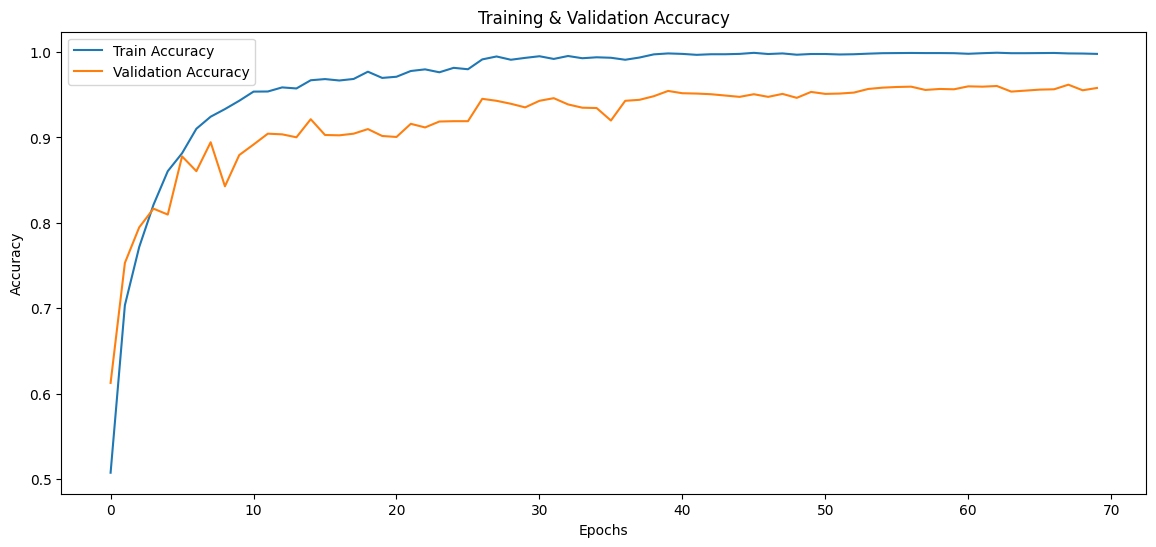

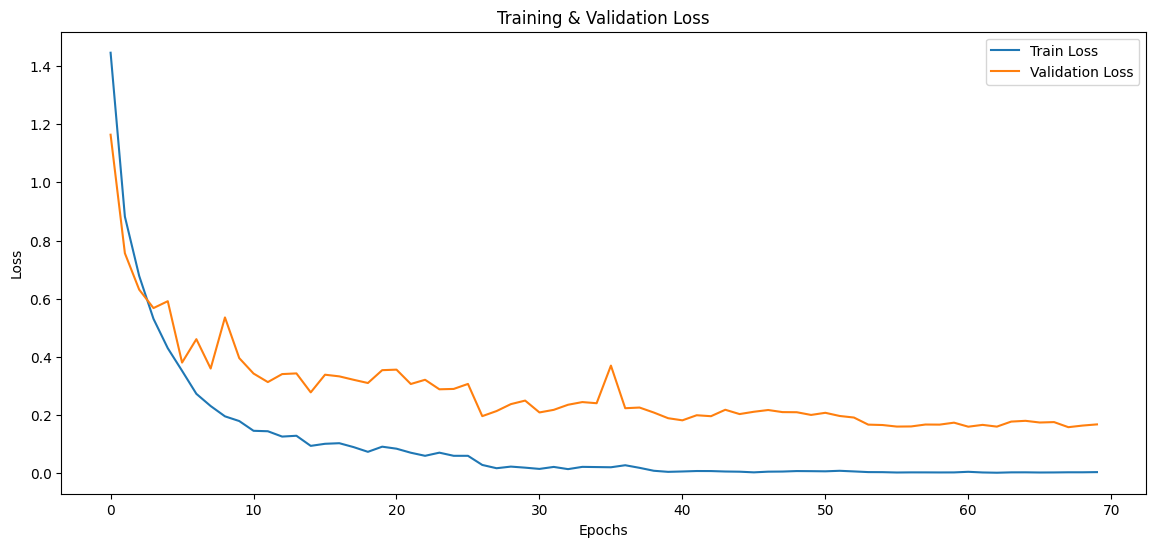

In [6]:
# Plot Akurasi
plt.figure(figsize=(14, 6))
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.grid(False)
os.makedirs("plot", exist_ok=True)
plt.savefig("plot/accuracy.png")
plt.show() 
    
# Plot Loss
plt.figure(figsize=(14, 6))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.grid(False)
plt.savefig("plot/loss.png")
plt.show()

# **Section 3. Evaluasi pada Test Set**

Evaluasi dijalankan terpisah untuk tiap test set dengan bobot model yang ada di memori setelah training selesai. Untuk tiap set ditampilkan loss, akurasi, *classification report* (precision, recall, F1 per genre), dan *confusion matrix* (disimpan sebagai `confusion_matrix_test{n}.png`).

Genre `rock` secara konsisten punya recall terendah di hampir semua test set.


🔍 Evaluasi Test Set 1
🎯 Test Loss: 0.0115
🎯 Test Accuracy: 0.9499

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.92      0.94      0.93       100
   classical       1.00      0.98      0.99       100
     country       0.89      0.97      0.93       100
       disco       0.96      0.99      0.98       100
      hiphop       0.98      0.95      0.96       100
        jazz       0.95      0.98      0.97        99
       metal       0.98      0.93      0.95       100
         pop       0.95      0.94      0.94       100
      reggae       0.96      0.96      0.96        99
        rock       0.91      0.86      0.89       100

    accuracy                           0.95       998
   macro avg       0.95      0.95      0.95       998
weighted avg       0.95      0.95      0.95       998



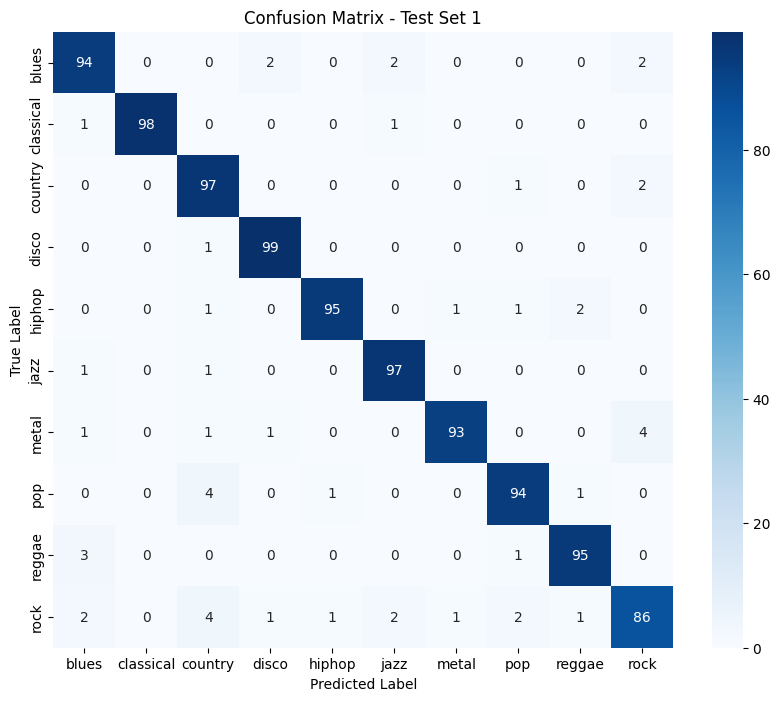


🔍 Evaluasi Test Set 2
🎯 Test Loss: 0.0217
🎯 Test Accuracy: 0.9143

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.97      0.89      0.93        35
   classical       0.94      0.97      0.96        35
     country       0.79      0.94      0.86        35
       disco       0.85      1.00      0.92        35
      hiphop       0.97      0.91      0.94        35
        jazz       0.90      1.00      0.95        35
       metal       0.89      0.89      0.89        35
         pop       1.00      0.83      0.91        35
      reggae       0.95      1.00      0.97        35
        rock       0.96      0.71      0.82        35

    accuracy                           0.91       350
   macro avg       0.92      0.91      0.91       350
weighted avg       0.92      0.91      0.91       350



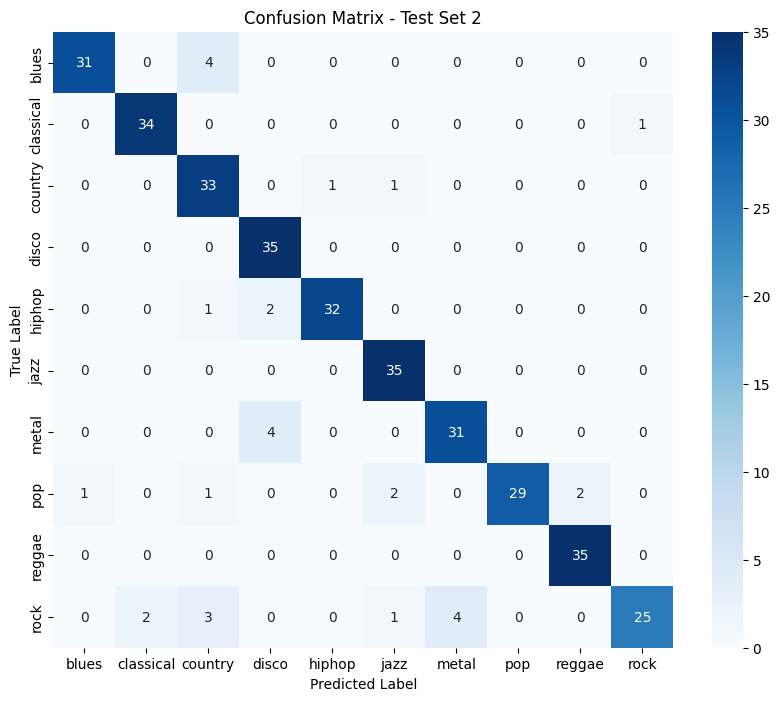


🔍 Evaluasi Test Set 3
🎯 Test Loss: 0.0127
🎯 Test Accuracy: 0.9457

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.92      0.94      0.93        35
   classical       1.00      1.00      1.00        35
     country       0.97      0.91      0.94        35
       disco       0.94      0.97      0.96        35
      hiphop       0.94      0.97      0.96        35
        jazz       0.85      1.00      0.92        35
       metal       0.94      0.97      0.96        35
         pop       0.91      0.91      0.91        35
      reggae       1.00      0.97      0.99        35
        rock       1.00      0.80      0.89        35

    accuracy                           0.95       350
   macro avg       0.95      0.95      0.95       350
weighted avg       0.95      0.95      0.95       350



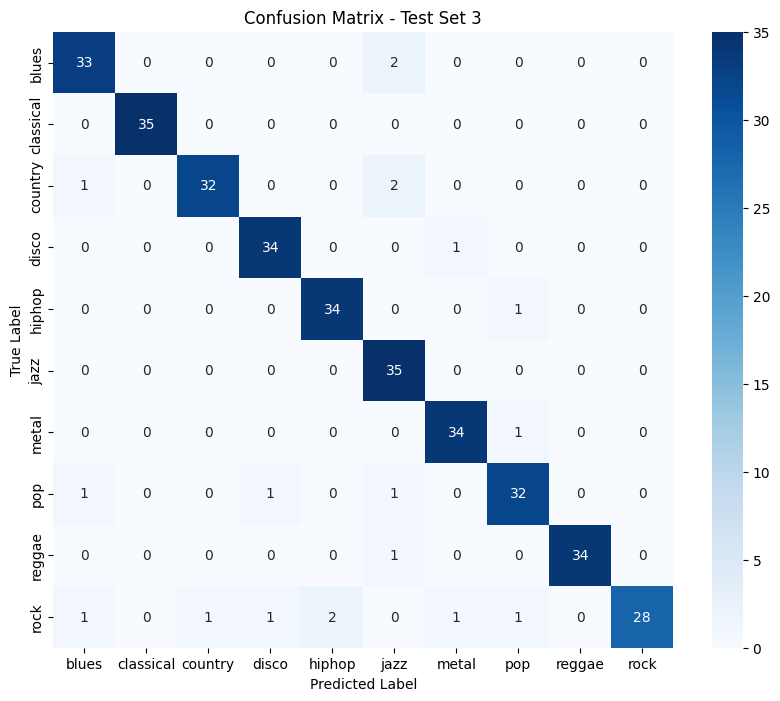


🔍 Evaluasi Test Set 4
🎯 Test Loss: 0.0268
🎯 Test Accuracy: 0.9229

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.78      0.91      0.84        35
   classical       1.00      1.00      1.00        35
     country       0.82      0.94      0.88        35
       disco       0.88      1.00      0.93        35
      hiphop       0.97      0.97      0.97        35
        jazz       0.94      0.97      0.96        35
       metal       1.00      0.83      0.91        35
         pop       1.00      0.77      0.87        35
      reggae       0.97      0.91      0.94        35
        rock       0.94      0.91      0.93        35

    accuracy                           0.92       350
   macro avg       0.93      0.92      0.92       350
weighted avg       0.93      0.92      0.92       350



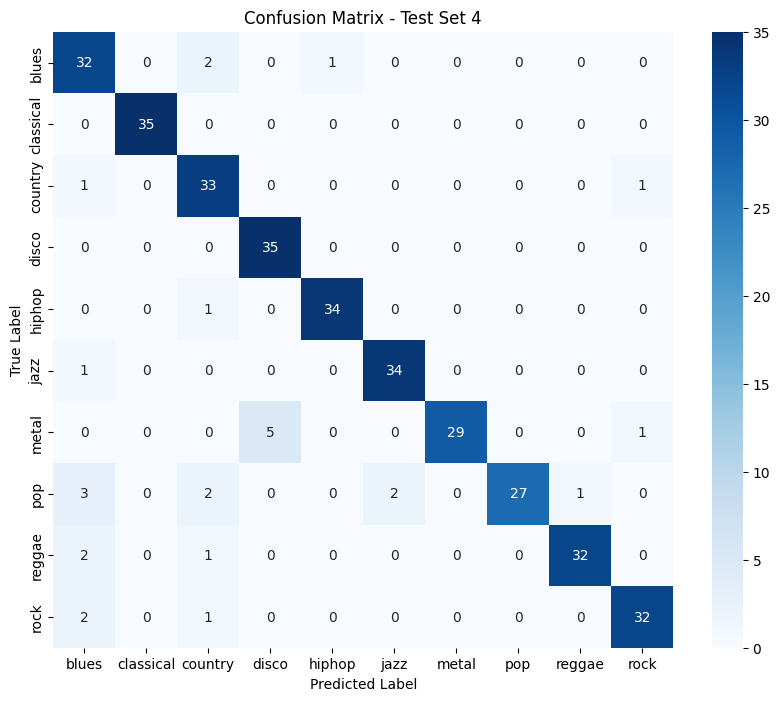


🔍 Evaluasi Test Set 5
🎯 Test Loss: 0.0156
🎯 Test Accuracy: 0.9286

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.94      0.97      0.96        35
   classical       1.00      1.00      1.00        35
     country       0.89      0.94      0.92        35
       disco       0.92      0.94      0.93        35
      hiphop       0.97      1.00      0.99        35
        jazz       0.86      0.89      0.87        35
       metal       0.97      0.94      0.96        35
         pop       0.86      0.91      0.89        35
      reggae       0.90      0.80      0.85        35
        rock       0.97      0.89      0.93        35

    accuracy                           0.93       350
   macro avg       0.93      0.93      0.93       350
weighted avg       0.93      0.93      0.93       350



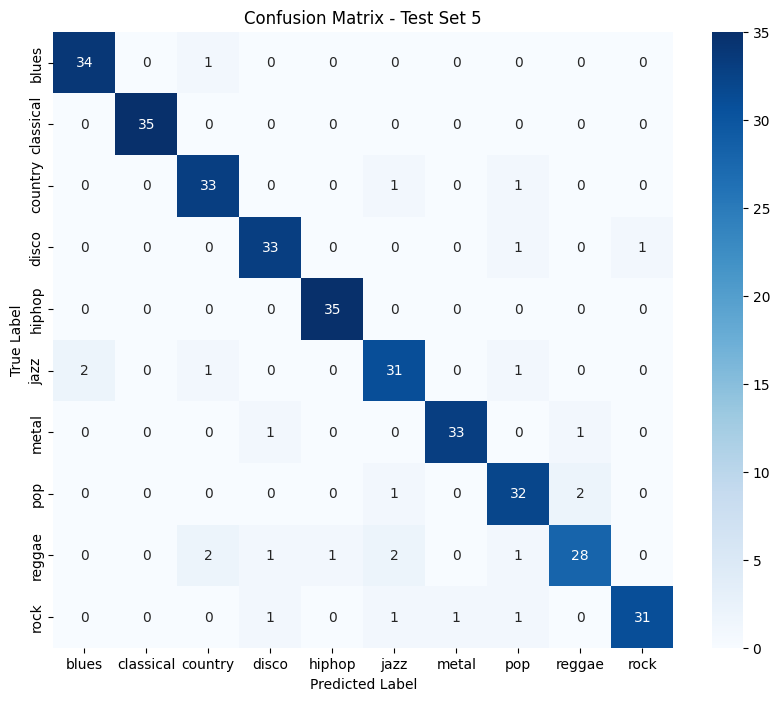


🔍 Evaluasi Test Set 6
🎯 Test Loss: 0.0265
🎯 Test Accuracy: 0.9229

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.94      0.91      0.93        35
   classical       0.81      1.00      0.90        35
     country       0.88      0.86      0.87        35
       disco       0.97      1.00      0.99        35
      hiphop       0.97      1.00      0.99        35
        jazz       0.81      1.00      0.90        35
       metal       0.97      0.94      0.96        35
         pop       0.97      0.89      0.93        35
      reggae       1.00      0.91      0.96        35
        rock       0.96      0.71      0.82        35

    accuracy                           0.92       350
   macro avg       0.93      0.92      0.92       350
weighted avg       0.93      0.92      0.92       350



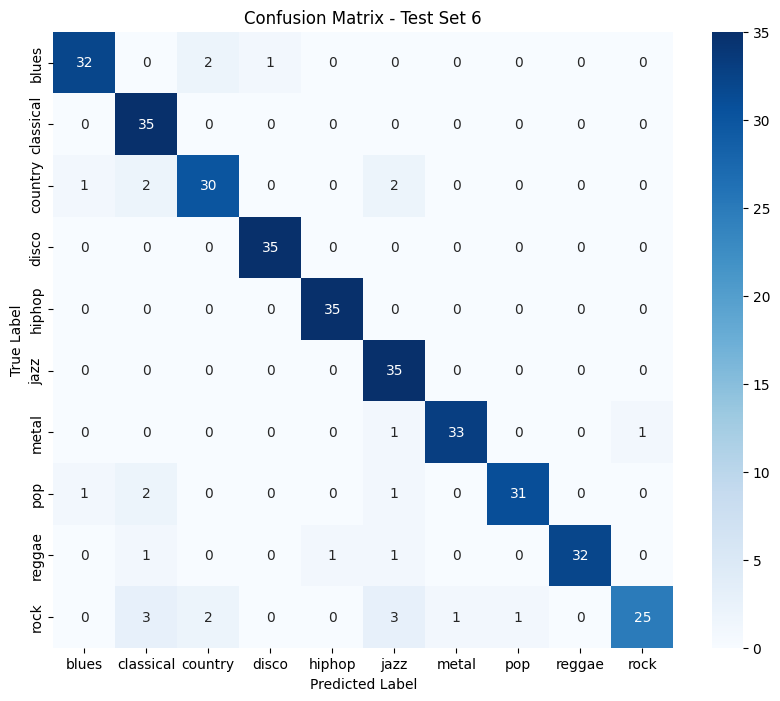


🔍 Evaluasi Test Set 7
🎯 Test Loss: 0.0096
🎯 Test Accuracy: 0.9571

📊 Classification Report:
              precision    recall  f1-score   support

       blues       0.97      0.89      0.93        35
   classical       0.97      1.00      0.99        35
     country       0.89      0.97      0.93        35
       disco       0.94      0.97      0.96        35
      hiphop       1.00      0.97      0.99        35
        jazz       0.95      1.00      0.97        35
       metal       0.97      0.91      0.94        35
         pop       0.97      0.97      0.97        35
      reggae       1.00      0.94      0.97        35
        rock       0.92      0.94      0.93        35

    accuracy                           0.96       350
   macro avg       0.96      0.96      0.96       350
weighted avg       0.96      0.96      0.96       350



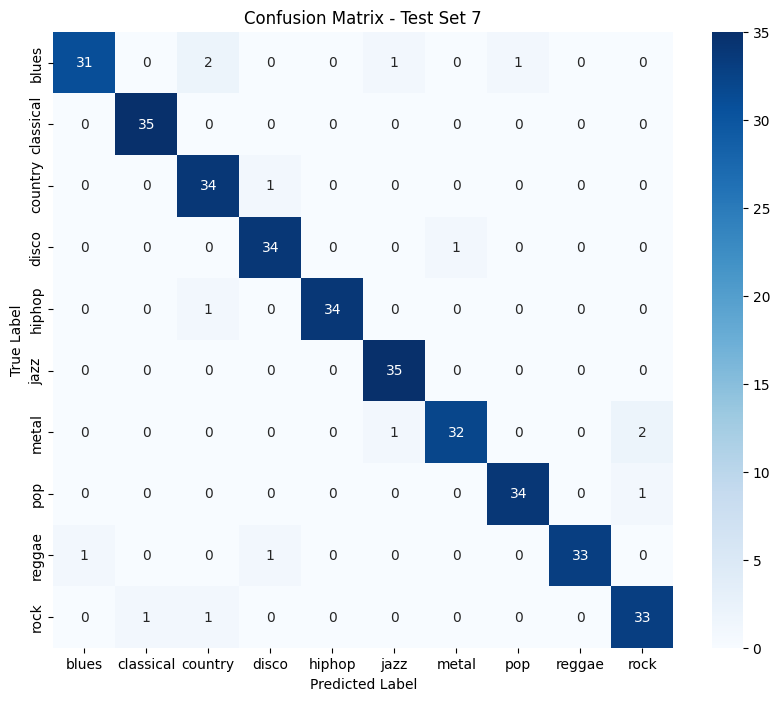

In [ ]:
# Membuat folder jika belum ada
os.makedirs("confusion_matrix", exist_ok=True)

for i, test_loader in enumerate(test_loaders):
    print(f"\n🔍 Evaluasi Test Set {i+1}")

    y_true = []
    y_pred = []
    test_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    test_loss /= len(test_loader.dataset)
    test_acc = (np.array(y_true) == np.array(y_pred)).mean()

    print(f"🎯 Test Loss: {test_loss:.4f}")
    print(f"🎯 Test Accuracy: {test_acc:.4f}")

    # --- Classification Report ---
    print("\n📊 Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # --- Confusion Matrix ---
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix - Test Set {i+1}")

    plt.savefig(
        f"confusion_matrix/confusion_matrix_test{i+1}.png",
        bbox_inches="tight",
        dpi=300
    )
    plt.show()
    plt.close()

print("\n✅ Evaluasi semua test set selesai!")

## **3.1 Prediksi & Ekspor CSV**

Untuk tiap test set, model memprediksi semua gambar dan hasilnya disimpan ke `prediction_test{n}.csv` dengan kolom:

- `filename`: nama file gambar
- `true_label`: genre sebenarnya
- `predicted_label`: genre hasil prediksi
- `confidence_level`: probabilitas softmax tertinggi
- `testing_time_sec`: waktu inferensi per gambar (rata-rata per batch)

In [ ]:
# Membuat folder jika belum ada
os.makedirs("prediction", exist_ok=True)

for i, (test_dataset, test_loader) in enumerate(zip(test_datasets, test_loaders)):
    print(f"📁 Menyimpan Prediksi Test Set {i+1}")

    filenames = []
    true_labels = []
    predicted_labels = []
    confidence_levels = []
    testing_times = []

    sample_idx = 0

    with torch.no_grad():
        for images, labels in test_loader:
            batch_start = time.time()

            images = images.to(device)
            outputs = model(images)

            batch_end = time.time()

            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)
            batch_confidences = np.max(probs, axis=1)

            true_classes = labels.numpy()

            batch_files = [
                os.path.basename(test_dataset.samples[sample_idx + j][0])
                for j in range(len(images))
            ]
            sample_idx += len(images)

            filenames.extend(batch_files)
            true_labels.extend([class_names[j] for j in true_classes])
            predicted_labels.extend([class_names[j] for j in preds])
            confidence_levels.extend(batch_confidences)

            batch_time = (batch_end - batch_start) / len(images)
            testing_times.extend([batch_time] * len(images))

    df_pred = pd.DataFrame({
        "filename": filenames,
        "true_label": true_labels,
        "predicted_label": predicted_labels,
        "confidence_level": confidence_levels,
        "testing_time_sec": testing_times
    })

    save_name = f"confusion_matrix/prediction_test{i+1}.csv"
    df_pred.to_csv(save_name, index=False)

    print(f"✅ Prediksi test {i+1} selesai → {save_name}")

print("\n🎵 Prediksi genre musik telah selesai.")

📁 Menyimpan Prediksi Test Set 1
✅ Prediksi test 1 selesai → prediction_test1.csv
📁 Menyimpan Prediksi Test Set 2
✅ Prediksi test 2 selesai → prediction_test2.csv
📁 Menyimpan Prediksi Test Set 3
✅ Prediksi test 3 selesai → prediction_test3.csv
📁 Menyimpan Prediksi Test Set 4
✅ Prediksi test 4 selesai → prediction_test4.csv
📁 Menyimpan Prediksi Test Set 5
✅ Prediksi test 5 selesai → prediction_test5.csv
📁 Menyimpan Prediksi Test Set 6
✅ Prediksi test 6 selesai → prediction_test6.csv
📁 Menyimpan Prediksi Test Set 7
✅ Prediksi test 7 selesai → prediction_test7.csv

🎵 Prediksi genre musik telah selesai.
